# Calibrate

Do imports.

In [115]:
import numpy as np
import matplotlib.pyplot as plt
import statistics
from ae483.tools import *
from ae483.mytools import *

## Find $l_1$

Load data for a flight in which the drone sat motionless on the hard floor.

Resample drone data.

You may find that some of the data at the start or end of your flight are garbage. For this reason, `resample_data_drone` has two optional arguments:

* `t_min_offset` is how many seconds you want to ignore (i.e., delete) at the start of the data
* `t_max_offset` is how many seconds you want to ignore (i.e., delete) at the end of the data

To use these arguments effectively, you'll want to plot the data first (evaluate the next three cells to do this, for example) and then go back and play with the offsets. We won't mention these arguments again, but you should consider using them, as necessary, with **every** new dataset you collect and analyze.

In [116]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('floor.json')

In [117]:
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0.15, t_max_offset=0.)

t = data_drone['time']
z_drone = data_drone['stateEstimate.z']

Resample mocap data.

In [118]:
data_mocap = resample_data_mocap(raw_data_mocap, t)

z_mocap = data_mocap['z']

Plot data.

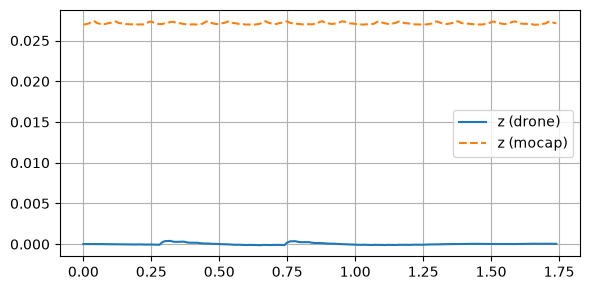

In [119]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
ax.plot(t, z_drone, label='z (drone)')
ax.plot(t, z_mocap, '--', label='z (mocap)')
ax.legend()
ax.grid()

Find $l_1$ by... **FIXME**.

In [120]:
l_1 = z_mocap[-1]
print(f'l_1 = {l_1:.5f}')

l_1 = 0.02711


# Find $l_2$

Load data for a flight in which the drone sat motionless on the carpet.

In [121]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('carpet.json')

Resample drone data.

In [122]:
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0., t_max_offset=0.)

t = data_drone['time']
z_drone = data_drone['stateEstimate.z']

Resample mocap data.

In [123]:
data_mocap = resample_data_mocap(raw_data_mocap, t)

z_mocap = data_mocap['z']

Plot data.

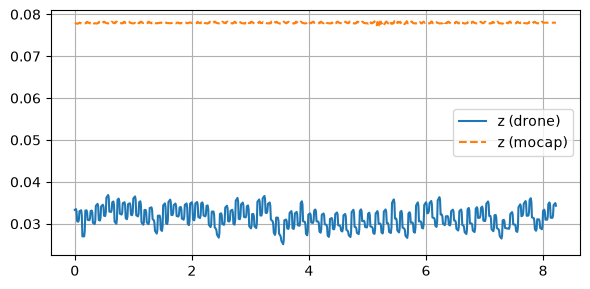

In [124]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
ax.plot(t, z_drone, label='z (drone)')
ax.plot(t, z_mocap, '--', label='z (mocap)')
ax.legend()
ax.grid()

Find $l_2$ by... **FIXME**.

In [125]:
l_2 = z_mocap[-1]
print(f'l_2 = {l_2:.5f}')

l_2 = 0.07799


# Find $l_3$ and $l_4$

Load data for a flight in which the drone sat motionless on "stilts" on the carpet.

In [126]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('stilts.json')

Resample drone data.

In [127]:
data_drone = resample_data_drone(raw_data_drone, t_min_offset=0.01, t_max_offset=0.)

t = data_drone['time']
z_drone = data_drone['stateEstimate.z']

Resample mocap data.

In [128]:
data_mocap = resample_data_mocap(raw_data_mocap, t)

z_mocap = data_mocap['z']

Plot data.

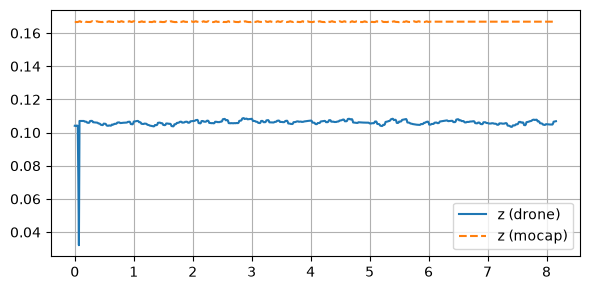

In [129]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
ax.plot(t, z_drone, label='z (drone)')
ax.plot(t, z_mocap, '--', label='z (mocap)')
ax.legend()
ax.grid()

Find $l_3$ by... **FIXME** and find $l_4$ by... **FIXME**.

In [130]:
l_3 = statistics.fmean(z_drone) - (l_2 - l_1)
l_4 = z_mocap[-1]
print(f'drone mean = {statistics.fmean(z_drone):.5f}')
print(f'l_3 = {l_3:.5f}')
print(f'l_4 = {l_4:.5f}')

drone mean = 0.10599
l_3 = 0.05511
l_4 = 0.16687


# Find $d_1$ and $d_2$

Find $d_1$ by... **FIXME**.

In [131]:
d_1 = l_4 - l_3 - l_2 + l_1
print(f'd_1 = {d_1:.5f}')

d_1 = 0.06088


Find $d_2$ by... **FIXME**.

In [132]:
d_2 = l_1 - d_1
print(f'd_2 = {d_2:.5f}')

d_2 = -0.03377
